# 04 · Evaluation: Does Each Stage Earn Its Place?

**Project:** AI-Powered Semantic Product Discovery & Shopping Concierge · **Author:** Maaz Amjad

## Problem
The pipeline adds three things on top of plain search: semantic retrieval, LLM-parsed hard filters, and
personalization. Each must be shown to help (or honestly shown not to), on queries that were **never used for
tuning**.

## Data
25 benchmark queries (10 dev for tuning, **15 test for reporting**), 6 strata. Relevance labels by pooling the top 10 of
every system: 659 query–product pairs graded 0/1/2 by Gemini 3.8 Flash, 167 of them (25 %) re-graded blind by a human;
the human grade wins. 70 more pairs that only the personalized system surfaces were judged later (judge only). Personalization is also tested on 3,995 users' held-out last purchase.

## Approach
The ablation ladder of the technical spec: S1 TF-IDF → S2 BM25 → S3 dense → S4 dense + post-filter → S5 dense +
filter-first → S6 S5 + personalization (S5x = S5 + "not X" exclusions, reported separately). Metrics: Precision@K, pooled
Recall@K, NDCG@K, constraint adherence; 95 % bootstrap CIs over queries (1,000 resamples, seed 42) and paired bootstrap
for adjacent systems. With 15 test queries, differences are **indicative**, not statistically significant claims.

## Results (details below)
- **Semantic retrieval** is the clearest gain: dense S3 beats TF-IDF S1 on NDCG@10 by +0.25 [0.05, 0.48] (G2).
- **LLM-parsed filters** make every top-10 product obey every stated limit (adherence 1.00 vs 0.43–0.63, G3); the parser
  reaches F1 0.94 on test (G1). One added, unstated category (q09) is the main failure.
- **Filter-first vs post-filter** is a neutral result: identical top 10 on all 15 test queries; filter-first is cheaper.
- **Personalization** beats popularity on the next-item task (HitRate@10 6.3 % vs 2.8 %) but costs a little query relevance: −0.026 NDCG@10 [−0.044, −0.007] on test,
  while precision@10 is unchanged (−0.001 [−0.015, 0.010]): it keeps the relevant products and ranks them slightly lower.
- **Grounding** holds: 0 invented IDs, prices or brands in accepted answers. **Latency** misses the 6 s end-to-end target.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import load_config, set_seed
from src.evaluate import RESULTS_DIR, run_report, summary_table

set_seed(42)
cfg = load_config()
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#e8833a", "#b8b6ae", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})
pd.set_option("display.max_colwidth", 60, "display.width", 160)
EVAL = PROJECT_ROOT / "eval"
queries = pd.read_csv(EVAL / "queries.csv")
print(queries.groupby(["stratum", "split"]).size().unstack(fill_value=0))


split           dev  test
stratum                  
category_brand    2     3
descriptive       2     3
exact_term        1     1
negation          1     2
no_result         1     2
price             3     4


## 1. How trustworthy are the relevance labels?

pooled pairs 659, human-verified 167: exact agreement 81.4%, relevant-vs-not 91.6%


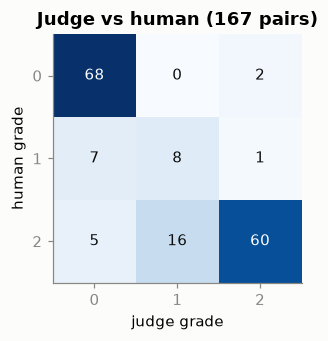

In [2]:
labels = pd.read_csv(RESULTS_DIR / "judge_labels.csv")
manual = pd.read_csv(EVAL / "manual_labels.csv")
agree = json.loads((RESULTS_DIR / "judge_agreement.json").read_text())
both = manual.merge(labels[["query_id", "product_id", "grade"]], on=["query_id", "product_id"])
cm = pd.crosstab(both.human_grade, both.grade, rownames=["human"], colnames=["judge"])
print(f"pooled pairs {len(labels)}, human-verified {agree['n']}: exact agreement {agree['exact']:.1%}, "
      f"relevant-vs-not {agree['binary']:.1%}")
fig, ax = plt.subplots(figsize=(3.8, 3.2))
ax.imshow(cm.values, cmap="Blues")
for (r, c), v in np.ndenumerate(cm.values):
    ax.text(c, r, v, ha="center", va="center", color="white" if v > cm.values.max() / 2 else INK)
ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xlabel("judge grade"); ax.set_ylabel("human grade")
ax.set_title("Judge vs human (167 pairs)"); ax.grid(False)
plt.tight_layout(); plt.show()


**Insight.** The judge and the human agree on the exact grade for 81 % of the verified pairs and on
relevant-vs-not for 92 %. The disagreements are not random: in 16 cases the human gave a 2 where the judge gave a 1, so
the judge is the *stricter* grader (it often withholds full credit when a listing does not state a wished-for attribute).
Because the human grade replaces the judge grade wherever both exist, these 167 pairs are human-resolved; the other 492
pooled pairs rely on the judge, so absolute scores are, if anything, slightly conservative.

## 2. Test-set results with 95 % confidence intervals
`run_report` recomputes everything from the saved runs and labels (no LLM calls) and saves `eval/results/test_*.csv`.

In [3]:
run_report(cfg, "test")
summary = pd.read_csv(RESULTS_DIR / "test_summary.csv")
paired = pd.read_csv(RESULTS_DIR / "test_paired.csv")
per_query = pd.read_csv(RESULTS_DIR / "test_per_query.csv")


test: 15 queries; mean [95% bootstrap CI]; NaN queries (nothing relevant in pool / no gold limit) dropped per metric
system               P@10               R@10            NDCG@10       adherence@10  n(NDCG)  n(adh) zero@5
    S1 0.460 [0.26, 0.65] 0.240 [0.16, 0.31] 0.398 [0.24, 0.58] 0.430 [0.25, 0.63]       14      10   0.00
    S2 0.507 [0.30, 0.71] 0.276 [0.19, 0.37] 0.506 [0.33, 0.70] 0.440 [0.22, 0.68]       14      10   0.00
    S3 0.673 [0.48, 0.85] 0.426 [0.30, 0.55] 0.647 [0.45, 0.82] 0.630 [0.38, 0.87]       14      10   0.00
    S4 0.793 [0.59, 0.97] 0.451 [0.36, 0.54] 0.738 [0.57, 0.89] 1.000 [1.00, 1.00]       14       8   0.13
    S5 0.793 [0.59, 0.97] 0.451 [0.36, 0.54] 0.738 [0.57, 0.89] 1.000 [1.00, 1.00]       14       8   0.13
   S5x 0.807 [0.60, 1.00] 0.463 [0.36, 0.57] 0.750 [0.59, 0.90] 1.000 [1.00, 1.00]       14       8   0.13
    S6 0.793 [0.59, 0.97] 0.452 [0.36, 0.54] 0.714 [0.55, 0.87] 1.000 [1.00, 1.00]       14       8   0.13

paired differences (to - f


error analysis: 3/15 queries failed; tag counts: {'parse error': 2, 'catalog gap': 2, 'over-filtering': 1, 'semantic retrieval failure': 1}; items graded >= 1 that violate gold limits: 9

search latency ms (retrieval + filtering):
        median_ms  p95_ms
system                   
S1           6.82    8.74
S2          21.95   32.30
S3           1.51    1.91
S4           3.13   16.96
S5           4.41   10.98
S5x          5.68  199.56


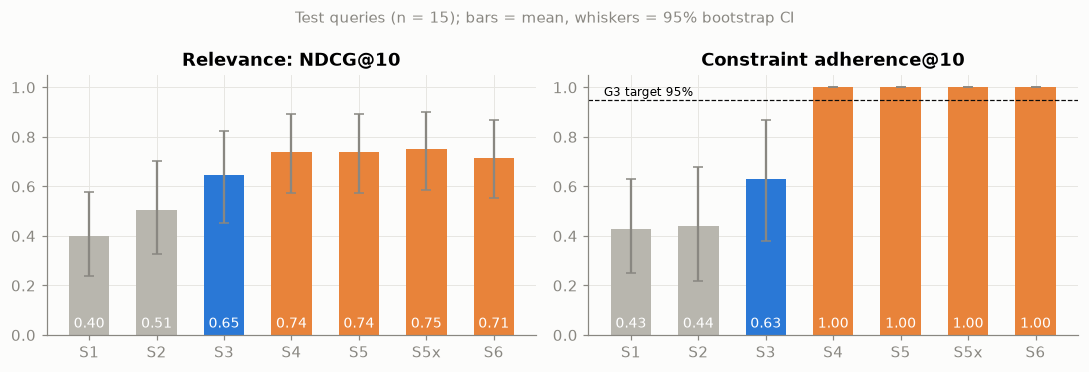

In [4]:
order = ["S1", "S2", "S3", "S4", "S5", "S5x", "S6"]
s = summary.set_index("system").loc[[x for x in order if x in summary.system.values]]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, metric, title in [(axes[0], "NDCG@10", "Relevance: NDCG@10"), (axes[1], "adherence@10", "Constraint adherence@10")]:
    err = [s[metric] - s[f"{metric}_lo"], s[f"{metric}_hi"] - s[metric]]
    colors = [GREY if x in ("S1", "S2") else BLUE if x in ("S3",) else ORANGE for x in s.index]
    ax.bar(s.index, s[metric], yerr=err, color=colors, capsize=3, width=0.6, ecolor=MUTED)
    ax.set_ylim(0, 1.05); ax.set_title(title)
    for i, v in enumerate(s[metric]):
        ax.text(i, 0.03, f"{v:.2f}", ha="center", color="white", fontsize=9)
axes[1].axhline(0.95, color=INK, lw=0.8, ls="--"); axes[1].text(-0.4, 0.965, "G3 target 95%", fontsize=8)
plt.suptitle("Test queries (n = 15); bars = mean, whiskers = 95% bootstrap CI", fontsize=10, color=MUTED)
plt.tight_layout(); plt.show()


**Insight.** Three steps up the ladder are visible. Dense retrieval (S3) beats the lexical baselines on relevance
(NDCG@10 0.65 vs 0.40 for TF-IDF and 0.51 for BM25). Adding the LLM-parsed hard filters (S4/S5) raises relevance again
(0.74) and, more importantly, lifts constraint adherence from 0.43 to 0.63 (unfiltered systems) to **1.00** (scored on the 8 limited queries
that return products): every
top-10 product obeys every stated price, category and brand limit, above the 95 % target (G3). Confidence intervals are
wide with 15 queries, so the ranking S1 < S3 < S5 is indicative. The personalized row (S6) is discussed in section 6.

## 3. What does each stage add? Paired differences on the same queries

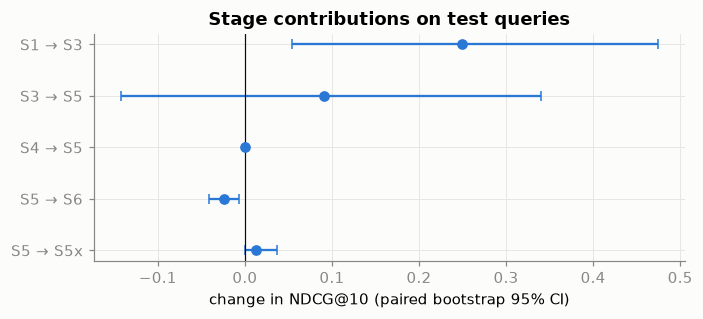

,from,to,metric,delta,lo,hi,queries
0,S1,S3,NDCG@10,0.249,0.054,0.475,14
1,S3,S5,NDCG@10,0.091,-0.143,0.340,14
2,S4,S5,NDCG@10,0.000,0.000,0.000,14
3,S5,S6,NDCG@10,-0.024,-0.042,-0.007,14
4,S5,S5x,NDCG@10,0.012,0.000,0.037,14
5,S1,S3,P@10,0.213,0.053,0.407,15
6,S3,S5,P@10,0.120,-0.120,0.340,15
7,S4,S5,P@10,0.000,0.000,0.000,15
8,S5,S6,P@10,-0.001,-0.015,0.010,15
9,S5,S5x,P@10,0.013,0.000,0.040,15


In [5]:
p = paired[paired.metric == "NDCG@10"].reset_index(drop=True)
labels_ = [f"{a} → {b}" for a, b in zip(p["from"], p["to"])]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.errorbar(p.delta, range(len(p)), xerr=[p.delta - p.lo, p.hi - p.delta], fmt="o", color=BLUE, capsize=3)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(range(len(p))); ax.set_yticklabels(labels_); ax.invert_yaxis()
ax.set_xlabel("change in NDCG@10 (paired bootstrap 95% CI)")
ax.set_title("Stage contributions on test queries")
plt.tight_layout(); plt.show()
display(paired.round(3))


**Insight.** Semantic retrieval is the clearest win: S1 → S3 improves NDCG@10 by +0.25 with a 95 % interval
that excludes zero [0.05, 0.48] (G2). Filtering (S3 → S5) adds +0.09 on average, but its interval spans zero because
filters only matter on the queries that state limits, and on q09 a wrong filter hurt (section 8). Exclusions
(S5 → S5x) add a small, consistent +0.01 on the two negation queries. S4 → S5 is exactly zero: see section 4.

## 4. Filter-first vs post-filter (S5 vs S4)
S4 retrieves K = 100, filters, and doubles K (up to 1,000) until 10 products survive; S5 searches only inside the allowed set.

In [6]:
info = pd.read_csv(RESULTS_DIR / "run_info.csv")
t = info[info.split == "test"]
cmp = t[t.system.isin(["S4", "S5"])].pivot(index="query_id", columns="system", values="pool_len")
print("S4 K used on test queries:", t[t.system == "S4"].k_used.value_counts().sort_index().to_dict())
print(f"candidate pool, median: S4 {cmp.S4.median():.0f} vs S5 {cmp.S5.median():.0f}; "
      f"queries where S4's pool is smaller: {(cmp.S4 < cmp.S5).sum()} of {len(cmp)}")
same = per_query[per_query.system.isin(["S4", "S5"])].pivot(index="query_id", columns="system", values="NDCG@10")
print("test queries with identical S4/S5 NDCG@10:", int((same.S4.fillna(-1) == same.S5.fillna(-1)).sum()), "of", len(same))
print(t[t.system.isin(["S4", "S5"])].groupby("system").search_ms.describe(percentiles=[0.5, 0.95])[["50%", "95%", "max"]].round(1))


S4 K used on test queries: {100.0: 12, 800.0: 1, 1000.0: 2}
candidate pool, median: S4 60 vs S5 200; queries where S4's pool is smaller: 11 of 15
test queries with identical S4/S5 NDCG@10: 15 of 15
        50%   95%   max
system                 
S4      3.1  17.0  21.0
S5      4.4  11.0  13.6


**Insight.** A neutral result, reported as such: on all 15 test queries the post-filter design (S4) returns the
same top 10 as filter-first (S5), because S4 keeps doubling K until 10 products survive. The cost shows up elsewhere:
S4 needed K = 800 or 1,000 on 3 queries, its candidate pool is smaller than S5's on 11 of 15 queries (median 60 vs 200
products), and its worst-case search time is higher (p95 17 ms vs 11 ms). So filter-first is not more *accurate* here
for a 10-item list; it is simpler, has bounded cost, and keeps a full pool for re-ranking (which personalization needs).

## 5. Query parsing: parse F1 (G1)

In [7]:
from src.evaluate import HARD_FIELDS, load_parsed, micro_f1, parse_counts
rows = []
for split, files in [("dev", {"v1 (first prompt)": "parsed_queries_dev_v1.jsonl", "v2 (final)": "parsed_queries_dev.jsonl"}),
                     ("test", {"v2 (final)": "parsed_queries_test.jsonl"})]:
    gold = queries[queries.split == split]
    for name, f in files.items():
        pred = pd.read_json(RESULTS_DIR / f, lines=True)
        c = parse_counts(pred, gold)
        h = micro_f1(c[c.field.isin(HARD_FIELDS)])
        rows.append({"split": split, "prompt": name, "F1": h["f1"], "precision": h["precision"], "recall": h["recall"]})
display(pd.DataFrame(rows).round(3))


,split,prompt,F1,precision,recall
0,dev,v1 (first prompt),0.800,0.667,1.0
1,dev,v2 (final),1.000,1.000,1.0
2,test,v2 (final),0.938,0.882,1.0


**Insight.** The final parser prompt reaches F1 = 0.94 on the held-out test queries (precision 0.88, recall 1.00),
above the 0.85 target (G1). It never misses a stated limit; its errors are additions: twice it added a category the user
did not state (*Ice Makers* for q09 and q15). On q15 that was harmless, but on q09 it removed the very parts the user
wanted (section 8). The dev score of 1.00 was reached by tuning the prompt on dev, which is why only the test number is
reported as the result.

## 6. Personalization
### Experiment B: predict each user's next purchase (3,995 users)

,method,users,hit@10,hit@10_lo,hit@10_hi,ndcg@10,ndcg@10_lo,ndcg@10_hi
0,random,3995,0.0015,0.0003,0.0028,0.0005,0.0001,0.0010
1,popularity,3995,0.0278,0.0228,0.0328,0.0154,0.0125,0.0183
2,profile,3995,0.0401,0.0340,0.0466,0.0202,0.0169,0.0238
3,blend,3995,0.0631,0.0561,0.0703,0.0361,0.0315,0.0408


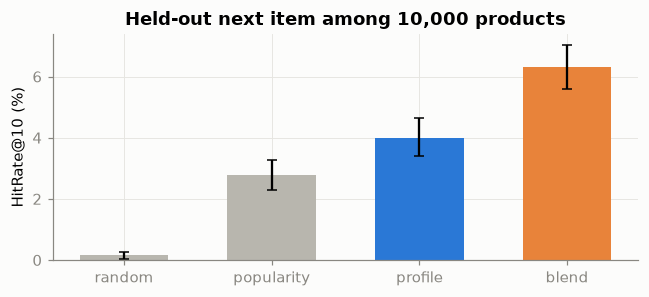

In [8]:
expb = pd.read_csv(RESULTS_DIR / "exp_b_summary.csv")
display(expb.round(4))
fig, ax = plt.subplots(figsize=(6, 2.8))
err = [expb["hit@10"] - expb["hit@10_lo"], expb["hit@10_hi"] - expb["hit@10"]]
ax.bar(expb.method, expb["hit@10"] * 100, yerr=np.array(err) * 100, color=[GREY, GREY, BLUE, ORANGE], capsize=3, width=0.6)
ax.set_ylabel("HitRate@10 (%)"); ax.set_title("Held-out next item among 10,000 products")
plt.tight_layout(); plt.show()


**Insight.** Personalization clearly works for its own task (G4, second half). Predicting each user's held-out
last purchase among 10,000 products, the blended score (profile + popularity) puts it in the top 10 for 6.3 % of users,
versus 2.8 % for the popularity baseline, 4.0 % for the profile alone and 0.15 % for random (the expected 10 / 10,000).
The intervals do not overlap. Popularity here is counted from the users' earlier interactions only, so the held-out
purchase cannot leak into its own score.

### Experiment A: does personalization hurt query relevance? (test queries, 8 users)

In [9]:
from src.data import load_interactions
from src.evaluate import CONDENSE_DEPTH, bootstrap_ci, experiment_a, load_parsed, run_s6
from src.personalize import pick_users

# Re-rank to depth 50 (no LLM): judged-only lists then still hold 10 items after unjudged ones are dropped.
test_q = queries[queries.split == "test"]
users = pick_users(load_interactions(), n=8, min_interactions=10, seed=cfg["seed"])
runs_s6, shift = run_s6(test_q, load_parsed(), cfg, users, depth=CONDENSE_DEPTH)
qrels = pd.read_csv(EVAL / "qrels.csv")
a = experiment_a(runs_s6, shift, qrels[qrels.query_id.isin(test_q.query_id)])
print(f"(user, query) pairs: {len(a)}; S6 top-10 items without a label: {a['unjudged@10'].mean():.1%}")
display(a[["delta_NDCG@10", "delta_NDCG@10_judged_only", "kendall_tau", "overlap@10"]].describe().loc[["mean", "50%", "min", "max"]].round(3))
per_q = a.groupby("query_id")["delta_NDCG@10_judged_only"].mean()
mean, lo, hi = bootstrap_ci(per_q, cfg["eval"]["bootstrap_resamples"], cfg["seed"])
print(f"judged-only change S5 -> S6, averaged over users then queries: {mean:+.3f} [{lo:+.3f}, {hi:+.3f}]")
display(a.groupby("user_id")[["delta_NDCG@10_judged_only", "kendall_tau", "overlap@10"]].mean().round(3))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

(user, query) pairs: 104; S6 top-10 items without a label: 0.0%


,delta_NDCG@10,delta_NDCG@10_judged_only,kendall_tau,overlap@10
mean,-0.026,-0.026,0.798,0.797
50%,0.000,0.000,0.805,0.800
min,-0.129,-0.129,0.648,0.400
max,0.069,0.069,0.892,1.000


judged-only change S5 -> S6, averaged over users then queries: -0.026 [-0.044, -0.007]


,delta_NDCG@10_judged_only,kendall_tau,overlap@10
user_id,,,
AEFKZBHTTKORKH6XVTK2DODAGANA,-0.028,0.807,0.823
AFYCZCWFENADZTSDQYNW5H2ROTOQ,-0.017,0.784,0.808
AFYQH7QVCV6BVHY5EQT7NNUMMEZA,-0.014,0.801,0.777
AGQY2K37UZDU6GIWAYQIM4LE3FOA,-0.020,0.812,0.792
AH2MO6H4FPFMYZABTZHOPY5KIVGA,-0.038,0.790,0.785
AH7F5U5WVX6XOALIPIFU2C7EPGZA,-0.036,0.792,0.800
AHJYTHKL7J6QCU5YS4WSXWMLRKOA,-0.023,0.798,0.800
AHYKYOVX365UEJD72HQ3YNHPZVXQ,-0.031,0.803,0.792


**Insight.** Personalization changes the order a lot (Kendall tau 0.80 over the pool, 80 % of the top 10 kept) and
costs a little query relevance, consistently: S6 is −0.026 NDCG@10 below S5 [−0.044, −0.007], and all 8 users are
slightly negative (−0.014 to −0.038). Of the 104 (user, query) pairs, 48 lose, 43 are unchanged and 13 gain; the largest
losses are on q10 and q19 (−0.08) and q02 (−0.06). Precision@10 barely moves (section 2: −0.001), so S6 keeps the
relevant products but places some of them lower. Every item in S6's top 10 is labelled, so the plain and judged-only
numbers agree. The spec expected a small or neutral effect; it is small and negative. On dev the same weights gave
+0.02, a reminder that 10 dev queries are a weak guide.

### Weight sensitivity (dev queries; weights were kept at the spec values)

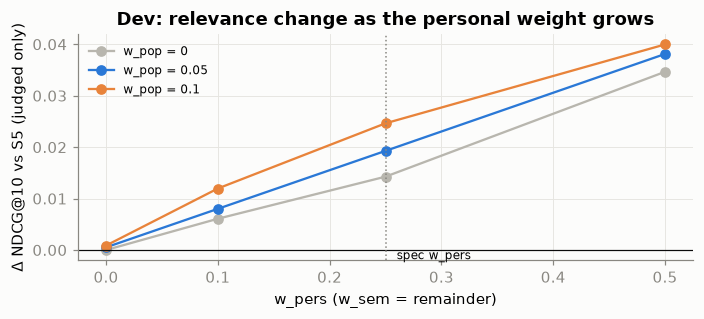

,weights,delta_ndcg_judged_only,delta_ndcg,unjudged,kendall_tau,overlap
0,"0.4,0.5,0.1",0.040,-0.131,0.304,0.431,0.499
1,"0.45,0.5,0.05",0.038,-0.096,0.247,0.467,0.553
2,"0.5,0.5,0",0.035,-0.071,0.200,0.499,0.597
3,"0.65,0.25,0.1",0.025,0.021,0.007,0.739,0.831
4,"0.7,0.25,0.05",0.019,0.019,0.000,0.759,0.850
5,"0.75,0.25,0",0.014,0.012,0.007,0.775,0.861
6,"0.8,0.1,0.1",0.012,0.010,0.003,0.893,0.940
7,"0.85,0.1,0.05",0.008,0.008,0.000,0.907,0.953
8,"0.9,0,0.1",0.001,-0.006,0.011,0.956,0.967
9,"0.9,0.1,0",0.006,0.006,0.000,0.915,0.954


In [10]:
sens = pd.read_csv(RESULTS_DIR / "weight_sensitivity_dev.csv")
sens[["w_sem", "w_pers", "w_pop"]] = sens.weights.str.split(",", expand=True).astype(float)
fig, ax = plt.subplots(figsize=(6.5, 3))
for w_pop, color in zip([0.0, 0.05, 0.1], [GREY, BLUE, ORANGE]):
    d = sens[sens.w_pop == w_pop].sort_values("w_pers")
    ax.plot(d.w_pers, d.delta_ndcg_judged_only, "o-", color=color, label=f"w_pop = {w_pop:g}")
ax.axhline(0, color=INK, lw=0.8); ax.axvline(0.25, color=MUTED, ls=":", lw=1); ax.text(0.26, ax.get_ylim()[0] * 0.9, "spec w_pers", fontsize=8)
ax.set_xlabel("w_pers (w_sem = remainder)"); ax.set_ylabel("Δ NDCG@10 vs S5 (judged only)")
ax.set_title("Dev: relevance change as the personal weight grows"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
display(sens[["weights", "delta_ndcg_judged_only", "delta_ndcg", "unjudged", "kendall_tau", "overlap"]].round(3))


**Insight.** Weights were kept at the spec values rather than tuned, as the spec allows. On dev queries, scored on
judged items only, the spec weights change NDCG@10 by +0.019, and no setting moves it by more than +0.04 or below 0: on
dev, personalization looks neutral to slightly positive for relevance. What grows with `w_pers` is the rank shift
(Kendall tau 0.76 at the spec weights, 0.43 at w_pers = 0.5) and the share of unlabelled items (0 % at the spec
weights, 20–30 % at w_pers = 0.5), which is why the plain NDCG change turns negative at high `w_pers` while the
judged-only one does not. Test (section 6) shows a small loss, so the dev result did not carry over.

## 7. Grounded generation (G5)

In [11]:
gen = pd.read_csv(RESULTS_DIR / "generation.csv")
llm = gen[gen.fallback.fillna("") != "no_result"]
print(f"LLM answers {len(llm)}: grounded first try {int(llm.grounded_first_try.sum())}, after one regeneration "
      f"{int(llm.grounded_final.sum())}; template fallbacks {int((gen.fallback == 'template').sum())}")
print(f"rejected attempts: invented ids {int(gen.bad_ids.sum())}, price mismatches {int(gen.bad_prices.sum())}, "
      f"brand mismatches {int(gen.bad_brands.sum())}")
print("recommended ids outside the retrieved set in accepted answers:",
      sum(len(set(json.loads(r)) - set(json.loads(k))) for r, k in zip(gen.recommended_ids, gen.ranked_ids)))
print(f"LLM-written words: max {llm.llm_words.max()}; rendered answers over 120 words: {int(gen.over_max_words.sum())}")


LLM answers 22: grounded first try 21, after one regeneration 22; template fallbacks 0
rejected attempts: invented ids 1, price mismatches 0, brand mismatches 0
recommended ids outside the retrieved set in accepted answers: 0
LLM-written words: max 105; rendered answers over 120 words: 11


**Insight.** Grounding holds (G5): zero recommended product IDs fall outside the retrieved set in any accepted
answer, and no accepted answer quotes a price or brand that is not in the product data. The validator rejected one first
draft (an invented product ID on dev query q04); the regenerated answer passed, so the template fallback was never
used. The LLM-written text stays within 120 words (max 105). With full product titles added by the renderer, 11 of 25
rendered answers exceed 120 words, so NFR-8 holds for the generated text but not for the rendered card list.

## 8. Error analysis (test queries, spec 10.8)

In [12]:
ea = pd.read_csv(RESULTS_DIR / "test_error_analysis.csv")
display(ea[["query_id", "stratum", "text", "S3", "S5", "S6", "failed", "tags", "label_conflicts"]].round(2))
print(ea.tags.fillna("").str.split("; ").explode().loc[lambda x: x != ""].value_counts())


,query_id,stratum,text,S3,S5,S6,failed,tags,label_conflicts
0,q02,price,quiet portable countertop ice maker under $150,0.23,0.67,0.61,False,NaN,0
1,q03,price,dryer heating element between $15 and $40,1.00,1.00,1.00,False,NaN,0
2,q05,price,"water filters for my coffee maker, less than $10",0.45,1.00,1.00,False,NaN,0
3,q06,price,dishwasher rack wheels under $12,0.63,1.00,1.00,False,NaN,0
4,q09,category_brand,Frigidaire brand ice maker assembly,0.95,0.22,0.19,True,parse error; over-filtering,1
5,q10,category_brand,beverage refrigerator for cans and wine,0.63,0.63,0.54,False,NaN,0
6,q11,category_brand,countertop dishwasher for a small apartment,1.00,1.00,1.00,False,NaN,2
7,q14,descriptive,remove chlorine taste from the water in my coffee machine,1.00,1.00,0.95,False,NaN,0
8,q15,descriptive,make chewable nugget ice at home for parties,1.00,1.00,0.96,True,parse error,0
9,q17,descriptive,replacement wick filter for my bedroom humidifier,0.48,0.48,0.51,True,semantic retrieval failure,0


tags
parse error                   2
catalog gap                   2
over-filtering                1
semantic retrieval failure    1
Name: count, dtype: int64


**Insight.** Five of 15 test queries are tagged, and three count as failures. The only failure caused by the core
pipeline is q09: an added *Ice Makers* category removed the Frigidaire parts the user wanted (NDCG 0.95 → 0.22). On q15
the same kind of added category was harmless (NDCG 1.00), but it is still a parse error. q17 ("replacement wick filter
for my bedroom humidifier") is a borderline *semantic retrieval failure*: dense search reaches NDCG@10 0.48, just under the
0.5 threshold (it was 0.503 before the personalized items joined the pool). The two catalog-gap queries (q24, q25) are
correct behaviour: nothing matches, and the system says so. No query is tagged *personalization drift* (S6 more than 0.1
below S5). Label conflicts (graded relevant although they break a stated limit) cluster on q24, where full-size Bosch
dishwashers were graded 1 for a *countertop* request.

### Post-hoc view: excluding the no-result stratum
No-result queries test the no-result path, and their ranking metrics reward systems that return *something*. This view was chosen after seeing the results, so it is secondary to section 2.

In [13]:
keep = set(queries[(queries.split == "test") & (queries.stratum != "no_result")].query_id)
s2 = summary_table(per_query[per_query.query_id.isin(keep)], cfg["eval"]["bootstrap_resamples"], cfg["seed"])
display(s2[["system", "queries", "NDCG@10", "NDCG@10_lo", "NDCG@10_hi", "P@10", "adherence@10"]].round(3))


,system,queries,NDCG@10,NDCG@10_lo,NDCG@10_hi,P@10,adherence@10
0,S1,13,0.429,0.261,0.606,0.531,0.538
1,S2,13,0.535,0.353,0.731,0.577,0.550
2,S3,13,0.628,0.443,0.807,0.738,0.788
3,S4,13,0.795,0.655,0.920,0.915,1.000
4,S5,13,0.795,0.655,0.920,0.915,1.000
5,S5x,13,0.808,0.664,0.933,0.931,1.000
6,S6,13,0.769,0.624,0.897,0.914,1.000


**Insight.** Without the two no-result queries the ladder is cleaner (S1 0.43, S3 0.63, S5 0.79) and S5's interval
moves clear of S1's; the conclusions do not change. This view was chosen after seeing the results, so the 15-query
table in section 2 remains the reported result.

## 9. Latency (NFR-1)

In [14]:
v1 = pd.read_csv(RESULTS_DIR / "generation_validator_v1.csv")
live = v1[v1.fallback.fillna("") != "no_result"]
lat = pd.DataFrame({
    "S5 retrieval + filtering (ms)": t[t.system == "S5"].search_ms.describe(percentiles=[0.5, 0.95])[["50%", "95%"]],
    "query encoding (ms)": t[t.system == "S5"].encode_ms.describe(percentiles=[0.5, 0.95])[["50%", "95%"]],
    "generation, live LLM (ms)": live.generate_ms.describe(percentiles=[0.5, 0.95])[["50%", "95%"]],
}).T.round(1)
lat.columns = ["median", "p95"]
display(lat)


,median,p95
S5 retrieval + filtering (ms),4.4,11.0
query encoding (ms),17.4,20.5
"generation, live LLM (ms)",5963.5,12664.4


**Insight.** Retrieval, filtering and ranking are fast on a CPU: S5 search takes a median 4 ms (p95 11 ms) and
query encoding about 17 ms, far below the 500 ms target (NFR-1). End-to-end time is dominated by the two LLM calls:
generation alone has a median of 6.0 s and p95 of 12.7 s on the free-tier Gemini endpoint (parse latency was not measured
because parses were cached), so the 6 s end-to-end p95 target is **not met**. A paid tier, a smaller output, or
streaming the answer would be the first fixes.

## 10. Limitations
- **Small benchmark.** 15 test queries give wide intervals; every difference is indicative, not a significance claim.
- **Pooling bias.** Labels come from the pooled top 10 of S1–S5x. Personalization surfaces items outside that pool; they
  were judged later in separate batches (70 pairs) and are not human-verified, so 23 % of all 729 labels are
  human-checked.
- **LLM judge.** 81 % exact agreement with a human; the judge is the stricter grader, and nine labels conflict with stated
  limits (reported, not relabelled).
- **Dev/test gap.** Weights and prompts were tuned on 10 dev queries; personalization looked slightly positive there (+0.02)
  and slightly negative on test (−0.03).
- **One catalog, English only, offline.** No online A/B test; personalization uses historic ratings as interactions.
- **Free-tier API.** 20 judge requests per day (failed 503 requests count) shaped the schedule; latency reflects that
  endpoint.